First 5 rows:
        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  

Dataset Shape:
(29531, 16)

Column Names:
Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 

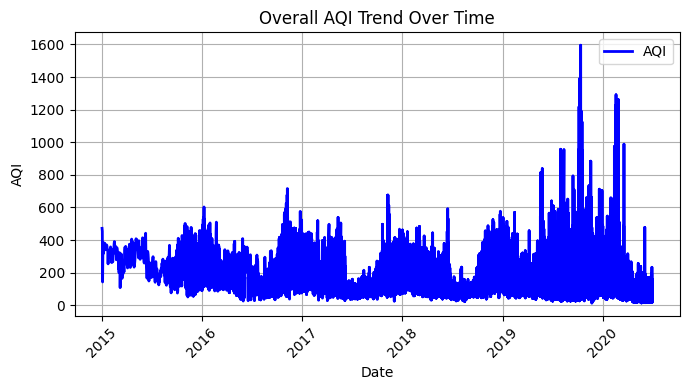

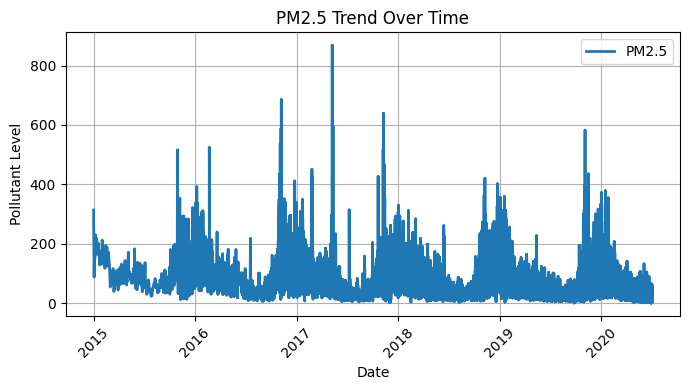

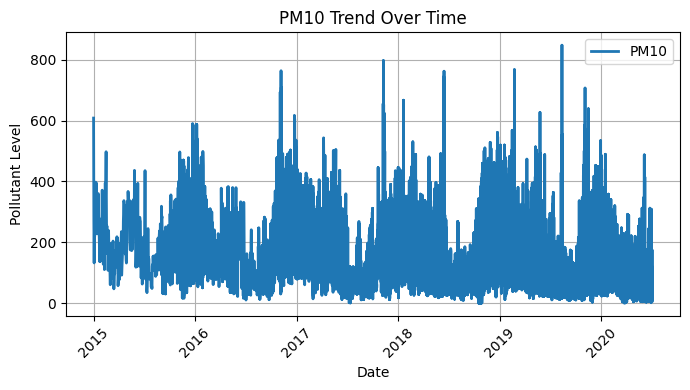

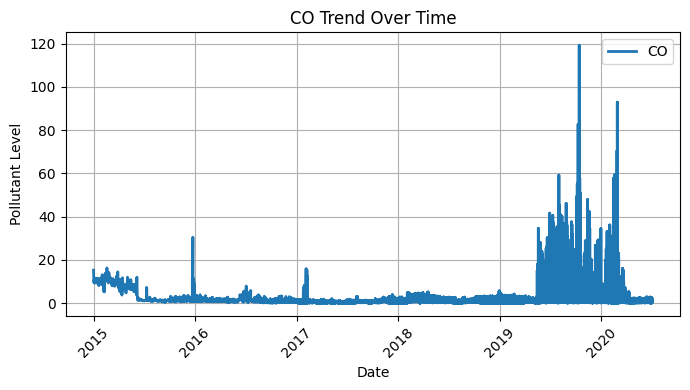

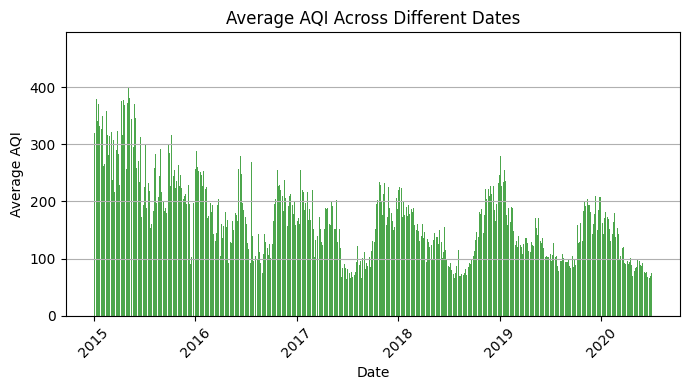

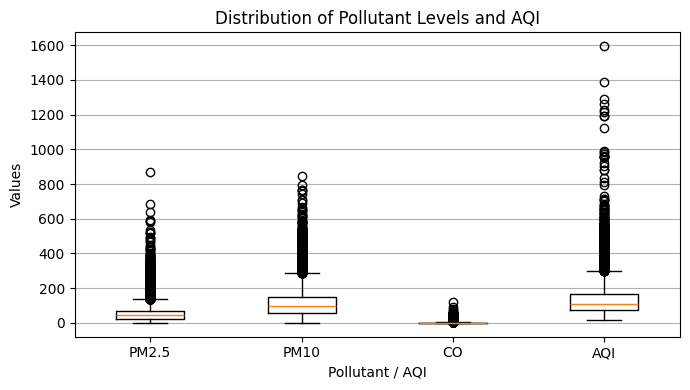

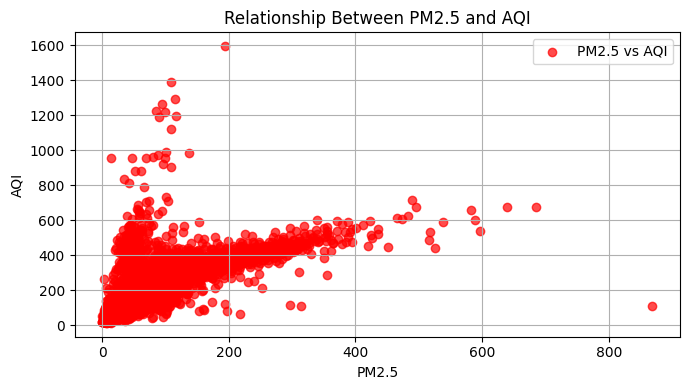

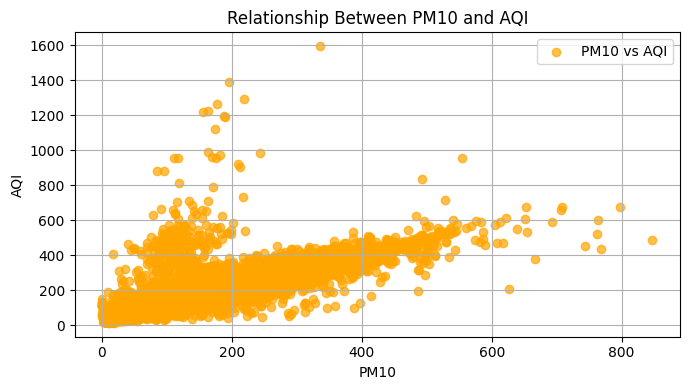

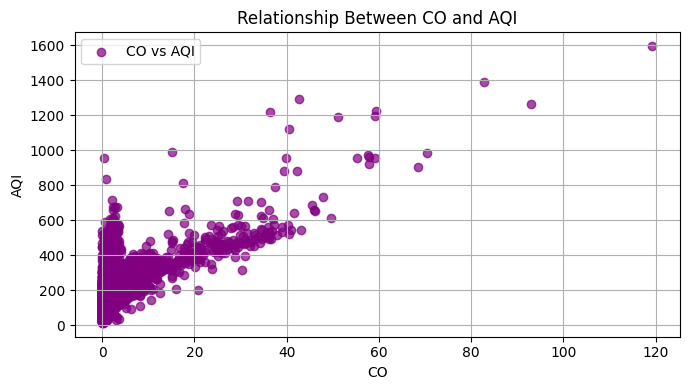

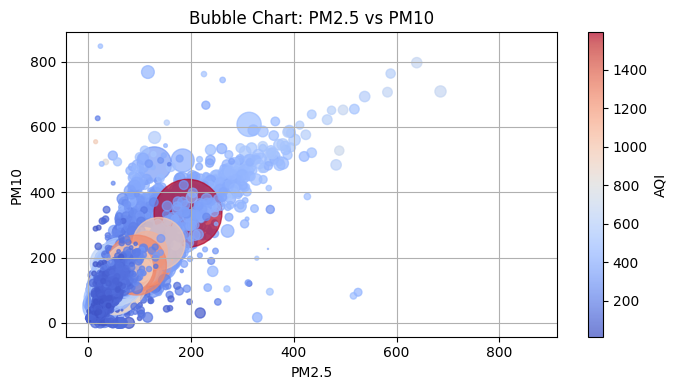


AQI Analysis Completed Successfully!


In [2]:
# 1. Import Required Libraries

import pandas as pd

import matplotlib.pyplot as plt

# 2. Load Dataset

data = pd.read_csv("city_day.csv")

print("First 5 rows:")

print(data.head())

print("\nDataset Shape:")

print(data.shape)

print("\nColumn Names:")

print(data.columns)

print("\nDataset Information:")

data.info()

print("\nMissing Values:")

print(data.isnull().sum())

# 3. Handle Missing Values

cleaned_data = data.dropna(

    subset=['Date', 'PM2.5', 'PM10', 'CO', 'AQI']

).copy()

print("\nCleaned Dataset:")

print(cleaned_data.head())

print("\nMissing Values After Cleaning:")

print(cleaned_data.isnull().sum())

# 4. Convert Date and Sort Dataset

cleaned_data['Date'] = pd.to_datetime(

    cleaned_data['Date'], errors='coerce'

)

cleaned_data.dropna(subset=['Date'], inplace=True)

cleaned_data.sort_values(by='Date', inplace=True)

# 5. Identify Relevant Variables

print("\nRelevant Variables:")

print(cleaned_data[['Date', 'PM2.5', 'PM10', 'CO', 'AQI']].head())

# 6. AQI Trend Over Time (Line Plot)

plt.figure(figsize=(7, 4))

plt.plot(

    cleaned_data['Date'],

    cleaned_data['AQI'],

    label='AQI',

    color='blue',

    linewidth=2

)

plt.xlabel('Date')

plt.ylabel('AQI')

plt.title('Overall AQI Trend Over Time')

plt.legend()

plt.grid(True)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

# 7. Individual Pollutant Trends (Line Plots)

pollutants = ['PM2.5', 'PM10', 'CO']

for pollutant in pollutants:

    plt.figure(figsize=(7, 4))

    plt.plot(

        cleaned_data['Date'],

        cleaned_data[pollutant],

        label=pollutant,

        linewidth=2

    )

    plt.xlabel('Date')

    plt.ylabel('Pollutant Level')

    plt.title(pollutant + ' Trend Over Time')

    plt.legend()

    plt.grid(True)

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()

# 8. Bar Plot: Average AQI by Date

aqi_by_date = (

    cleaned_data.groupby('Date')['AQI']

    .mean()

    .reset_index()

)

plt.figure(figsize=(7, 4))

plt.bar(

    aqi_by_date['Date'],

    aqi_by_date['AQI'],

    color='green',

    alpha=0.7

)

plt.xlabel('Date')

plt.ylabel('Average AQI')

plt.title('Average AQI Across Different Dates')

plt.xticks(rotation=45)

plt.grid(axis='y')

plt.tight_layout()

plt.show()

# 9. Box Plot: Distribution of Pollutants and AQI

plt.figure(figsize=(7, 4))

plt.boxplot([

    cleaned_data['PM2.5'],

    cleaned_data['PM10'],

    cleaned_data['CO'],

    cleaned_data['AQI']

])

plt.xticks(

    [1, 2, 3, 4],

    ['PM2.5', 'PM10', 'CO', 'AQI']

)

plt.xlabel('Pollutant / AQI')

plt.ylabel('Values')

plt.title('Distribution of Pollutant Levels and AQI')

plt.grid(axis='y')

plt.tight_layout()

plt.show()

# 10. Scatter Plot: PM2.5 vs AQI

plt.figure(figsize=(7, 4))

plt.scatter(

    cleaned_data['PM2.5'],

    cleaned_data['AQI'],

    alpha=0.7,

    color='red',

    label='PM2.5 vs AQI'

)

plt.xlabel('PM2.5')

plt.ylabel('AQI')

plt.title('Relationship Between PM2.5 and AQI')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# 11. Scatter Plot: PM10 vs AQI

plt.figure(figsize=(7, 4))

plt.scatter(

    cleaned_data['PM10'],

    cleaned_data['AQI'],

    alpha=0.7,

    color='orange',

    label='PM10 vs AQI'

)

plt.xlabel('PM10')

plt.ylabel('AQI')

plt.title('Relationship Between PM10 and AQI')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# 12. Scatter Plot: CO vs AQI

plt.figure(figsize=(7, 4))

plt.scatter(

    cleaned_data['CO'],

    cleaned_data['AQI'],

    alpha=0.7,

    color='purple',

    label='CO vs AQI'

)

plt.xlabel('CO')

plt.ylabel('AQI')

plt.title('Relationship Between CO and AQI')

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# 13. Bubble Chart

plt.figure(figsize=(7, 4))

plt.scatter(

    cleaned_data['PM2.5'],

    cleaned_data['PM10'],

    s=cleaned_data['CO'] * 20,

    c=cleaned_data['AQI'],

    cmap='coolwarm',

    alpha=0.7

)

plt.xlabel('PM2.5')

plt.ylabel('PM10')

plt.title('Bubble Chart: PM2.5 vs PM10')

plt.colorbar(label='AQI')

plt.grid(True)

plt.tight_layout()

plt.show()

print("\nAQI Analysis Completed Successfully!")